# Checkpoint 3

Estimating slow conduction in cardiac tissue is a key inverse problem in cardiac electrophysiology. In this checkpoint, the goal is to reconstruct a **spatially varying slow-conduction field** from electrogram-derived activation times (see Checkpoint 1).

We use the **eikonal equation**, which models activation time as a function of spatial position and local conduction velocity. This formulation enables efficient forward simulations and is well suited for PDE-constrained optimization, physics-informed neural networks, and data-driven approaches.
The objective is to estimate a continuous conduction velocity map by minimizing the discrepancy between simulated and observed activation times, capturing both the location and severity of conduction slowing.

In this checkpoint 3, the anisotropy ratio will be fixed to 3.0 for all patients.

In [1]:
# imports

import numpy as np
import matplotlib.pyplot as plt


# Physics-based model implementation

Implemenatation of the algorithm presented in :

Sermesant, Maxime, et al. "An anisotropic multi-front fast marching method for real-time simulation of cardiac electrophysiology." Functional Imaging and Modeling of the Heart: 4th International Conference, FIHM 2007, Salt Lake City, UT, USA, June 7-9, 2007. Proceedings 4. Springer Berlin Heidelberg, 2007.

In [2]:
import numpy as np
import heapq

def anisotropic_FMM_GPT(
    x0, y0, t0,
    X, Y,
    speed_input,
    sigma_11, sigma_12, sigma_22,
    N_edge=None
):
    """
    Fast-marching style solver with anisotropy and spatially varying speed.

    Parameters
    ----------
    x0, y0 : float
        Initial source location.
    t0 : float
        Initial activation time.
    X, Y : 2D ndarray
        Grid coordinates.
    speed_input : float, callable, or 2D ndarray
        Can be:
        - a scalar: constant speed everywhere
        - a function: speed_input(x, y)
        - a 2D array with same shape as X, Y
    sigma_11, sigma_12, sigma_22 : float
        Components of the inverse of conductivity tensor.
    N_edge : int or None
        Optional. If None, inferred from grid shape.

    Returns
    -------
    T_final : 2D ndarray
        Arrival time map.
    """

    nrows, ncols = X.shape
    if N_edge is None:
        N_edge = nrows - 1

    INF = 1e4
    P = np.linspace(0.0, 1.0, 11)

    # nearest grid node to source
    j0 = np.abs(X[0, :] - x0).argmin()
    i0 = np.abs(Y[:, 0] - y0).argmin()

    T = np.full((nrows, ncols), INF, dtype=float)
    T_final = np.full((nrows, ncols), INF, dtype=float)

    T[i0, j0] = t0
    T_final[i0, j0] = t0

    known = np.zeros((nrows, ncols), dtype=bool)

    # min-heap of (arrival_time, i, j)
    heap = [(t0, i0, j0)]

    def get_speed(i, j, x, y):
        if callable(speed_input):
            val = speed_input(x, y)
        elif np.isscalar(speed_input):
            val = speed_input
        else:
            val = speed_input[i, j]

        if val <= 0:
            raise ValueError(f"Speed must be positive. Got {val} at ({i}, {j}).")
        return val

    def metric_dist(xa, ya, xb, yb, speed_val):
        dx = xa - xb
        dy = ya - yb
        return np.sqrt(
            sigma_11 * dx * dx +
            2.0 * sigma_12 * dx * dy +
            sigma_22 * dy * dy
        ) / speed_val

    def update_fun(
        T_xi, T_x, T_y,
        X_xi, X_x, X_y,
        Y_xi, Y_x, Y_y,
        flag_known,
        i_xi, j_xi
    ):
        speed_val = get_speed(i_xi, j_xi, X_xi, Y_xi)

        if flag_known:
            dx = P * (X_xi - X_x) + (1.0 - P) * (X_xi - X_y)
            dy = P * (Y_xi - Y_x) + (1.0 - P) * (Y_xi - Y_y)

            triangle_vals = (
                P * T_x + (1.0 - P) * T_y
                + np.sqrt(
                    sigma_11 * dx * dx +
                    2.0 * sigma_12 * dx * dy +
                    sigma_22 * dy * dy
                ) / speed_val
            )
            cand = triangle_vals.min()
        else:
            cand = T_x + metric_dist(X_xi, Y_xi, X_x, Y_x, speed_val)

        return min(T_xi, cand)

    # side nodes used for triangle updates
    side_map = {
        (-1,  0): [(-1, +1), (-1, -1)],  # north
        (+1,  0): [(+1, +1), (+1, -1)],  # south
        ( 0, -1): [(+1, -1), (-1, -1)],  # west
        ( 0, +1): [(+1, +1), (-1, +1)],  # east
    }

    while heap:
        t_sel, i_sel, j_sel = heapq.heappop(heap)

        # ignore stale entries
        if known[i_sel, j_sel]:
            continue
        if t_sel > T_final[i_sel, j_sel]:
            continue

        known[i_sel, j_sel] = True

        # visit 4-neighbors
        for di, dj in [(-1, 0), (1, 0), (0, -1), (0, +1)]:
            ni, nj = i_sel + di, j_sel + dj

            if not (0 <= ni < nrows and 0 <= nj < ncols):
                continue
            if known[ni, nj]:
                continue

            new_T = INF

            for sdi, sdj in side_map[(di, dj)]:
                si, sj = i_sel + sdi, j_sel + sdj

                if not (0 <= si < nrows and 0 <= sj < ncols):
                    continue

                new_T = update_fun(
                    T_xi=new_T,
                    T_x=T_final[i_sel, j_sel],
                    T_y=T_final[si, sj],
                    X_xi=X[ni, nj], X_x=X[i_sel, j_sel], X_y=X[si, sj],
                    Y_xi=Y[ni, nj], Y_x=Y[i_sel, j_sel], Y_y=Y[si, sj],
                    flag_known=known[si, sj],
                    i_xi=ni, j_xi=nj
                )

            if new_T < T_final[ni, nj]:
                T[ni, nj] = new_T
                T_final[ni, nj] = new_T
                heapq.heappush(heap, (new_T, ni, nj))

    return T_final

# Eikonal equation

Let us consider the Eikonal model: find T(x,y)

\begin{aligned}
  & 80 \sqrt{ \nabla T(x,y) D \nabla T(x,y)} = 1  \,, \quad (x,y) \in [-2,2] \times [-2,2]\,,\\
  & u(x,y) = t_0,t_1  \,, \qquad \qquad \qquad \qquad \qquad x=x_0,x_1,y=y_0,y_1 \,, \\
\end{aligned}

where 
\begin{aligned}
D = 1\ \vec{b} \otimes \vec{b} + \frac{1}{a_{ratio}}  \ \vec{a} \otimes \vec{a},
\end{aligned}
being $ \vec{b} $ the given fiber orientation and $ \vec{a} $ the given cross-fiber orientation (orthogonal to $ \vec{b}$).

The unknown parameters of the problem are: 
- conduction velocity (tissue property common to all the patients),
- anisotropy ratio $a_{ratio}$ (tissue property common to all the patients),
- the slow conduction positions $(x_{SC},y_{SC})$ and its radius $r_{SC}$.

In [3]:
X_mesh, Y_mesh = np.meshgrid(np.linspace(-2.0,2.0,401), np.linspace(-2.0,2.0,401))

x0 = -1.5
y0 = -1

theta_fiber = 0
a_ratio = 5

theta0 = np.pi/2 - theta_fiber
a = np.array([np.cos(theta0), np.sin(theta0)]).T
b = np.array([np.cos(theta0-np.pi/2), np.sin(theta0-np.pi/2)]).T

D = ( (1/a_ratio)*np.tensordot( a, a,  axes=0) + np.tensordot( b, b,  axes=0)  )
print(D)

D_inv = np.linalg.inv(D)
sigma_11 = D_inv[0][0]
sigma_12 = D_inv[0][1]
sigma_21 = D_inv[1][0]
sigma_22 = D_inv[1][1]

xc, yc = 0.5, 0.5
r = 0.5

speed_field = lambda x, y: 20.0 if (x - xc)**2 + (y - yc)**2 <= r**2 else 80.0

activation_time = anisotropic_FMM_GPT( x0 , y0 , 0, X_mesh, Y_mesh, speed_field, sigma_11,sigma_12, sigma_22, N_edge=200 )




[[1.0000000e+00 1.2246468e-17]
 [1.2246468e-17 2.0000000e-01]]


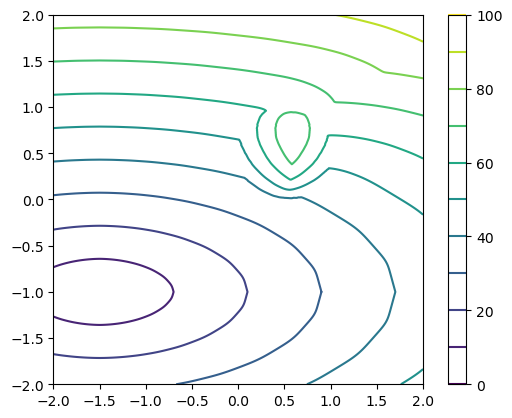

In [4]:

plt.contour(X_mesh, Y_mesh, activation_time*1000 , 10) 
plt.gca().set_aspect(1)
plt.colorbar()

In [5]:
N_samples = 1

np.random.seed(32)

measurements_dataset = []
groundtruth_dataset = []

for i_sample in range(N_samples):

    x0 = np.random.uniform(low=1.5,high=1.5)
    y0 = np.random.uniform(low=-1.5,high=1.5)
    x1 = np.random.uniform(low=1.5,high=1.5)
    y1 = np.random.uniform(low=-1.5,high=1.5)
    theta_fiber = 0.0
    a_ratio = np.random.uniform(low=1,high=9)

    theta0 = np.pi/2 - theta_fiber
    a = np.array([np.cos(theta0), np.sin(theta0)]).T
    b = np.array([np.cos(theta0-np.pi/2), np.sin(theta0-np.pi/2)]).T

    D = ( (1/a_ratio)*np.tensordot( a, a,  axes=0) + np.tensordot( b, b,  axes=0)  )
    print(D)

    D_inv = np.linalg.inv(D)
    sigma_11 = D_inv[0][0]
    sigma_12 = D_inv[0][1]
    sigma_21 = D_inv[1][0]
    sigma_22 = D_inv[1][1]

    # compute activation time
    activation_time = anisotropic_FMM_GPT( x0 , y0 , 0.0, X_mesh, Y_mesh, speed_field, sigma_11,sigma_12, sigma_22, N_edge=200 )

    # rescaling in ms
    activation_time = activation_time*1e3

    # measurements location
    Spline_spacing = [0.5, 0.7, 1.3, 1.5]
    Angles_spacing =  [np.pi/10.0+0, np.pi/10.0+(2)*np.pi/5, np.pi/10.0+(4)*np.pi/5, np.pi/10.0+(6)*np.pi/5, np.pi/10.0+(8)*np.pi/5 ]
    
    index_extracted = []
    x_meas = []
    y_meas = []
    time_meas = []

    for i in range(4):
        #print(i)
        for j in range(5):
            #print(j)
            MeasMat = (X_mesh - Spline_spacing[i]*np.cos(Angles_spacing[j]) )**2 + (Y_mesh - Spline_spacing[i]*np.sin(Angles_spacing[j]) )**2
            [i_sel, j_sel] = np.unravel_index(MeasMat.argmin(), MeasMat.shape) 
            index_extracted.append(i_sel)
            x_meas.append(X_mesh[i_sel,j_sel])
            y_meas.append(Y_mesh[i_sel,j_sel])
            time_meas.append(activation_time[i_sel,j_sel])

    measurements_dataset.append( [ x_meas, y_meas, time_meas ] )
    groundtruth_dataset.append([activation_time])

[[1.00000000e+00 8.88280440e-18]
 [8.88280440e-18 1.45067205e-01]]


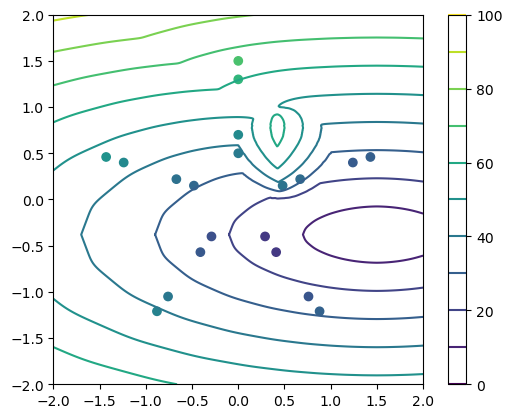

In [6]:
plt.figure(1)
plt.scatter( x_meas, y_meas, c=time_meas, vmin= 0, vmax=np.max(activation_time) )
plt.contour(X_mesh, Y_mesh, activation_time , 10)
plt.gca().set_aspect(1)
plt.colorbar()

# Checkpoint 3

Implement your algorithm to process the traces of the 20 unipolar electrogram signals and identify the center and radius of the slow conduction region.

The algorithm must return the following outputs:

1. **slow conduction fields evaluated on a 16x16 grid** 


Provide your algorithm's implementation in this notebook usign the signature defined below.

In [8]:
# load data
signals = np.load('checkpoint3dataset.npy')

# select event to be display
ind_event = 4

signals_event = signals[ind_event,:,:]

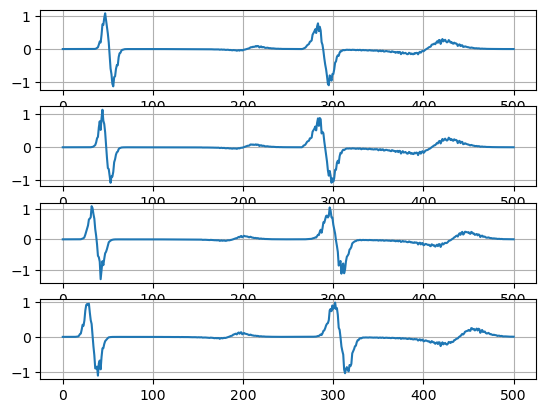

In [9]:
# select a spline (options: 0,1,2,3,4)
ind_spline = 0
# plot signals

plt.figure(1+ind_spline)
countEL = 1
for indS in np.arange(ind_spline*4,(ind_spline+1)*4,1):
    plt.subplot(4,1,countEL)
            
    plt.plot(signals[ind_event,indS,:])
    plt.grid(True)

    countEL = countEL + 1

plt.show()

In [10]:
def load_and_plot_velocity_fields(
    filename,
    sim_idx=0,
    N=None,
    M=None,
    h=None
):
    velocity_fields = np.load(filename)

    field16 = velocity_fields[sim_idx]

    if N is not None and M is not None and h is not None:
        step_x = N // 16
        step_y = M // 16

        ix = np.arange(0, step_x * 16, step_x)
        iy = np.arange(0, step_y * 16, step_y)

        Lx_sub = ix[-1] * h
        Ly_sub = iy[-1] * h

        extent = [0, Lx_sub, 0, Ly_sub]
    else:
        extent = None

    plt.figure(figsize=(5, 4))
    plt.imshow(
        field16.T,
        origin='lower',
        extent=extent,
        cmap='viridis',
        aspect='equal'
    )
    plt.colorbar(label='Conduction scale')
    plt.title(f'Case {sim_idx} - velocity field (16x16)')
    plt.xlabel('x')
    plt.ylabel('y')
    plt.tight_layout()
    plt.show()

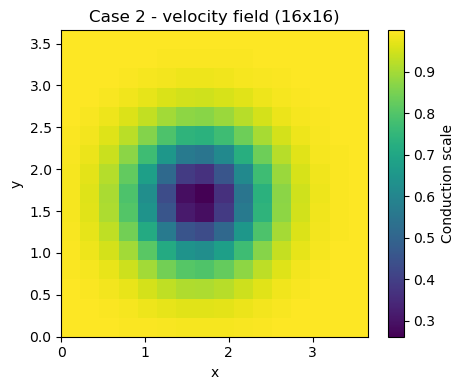

In [11]:
N = np.int32(2*164)
M = np.int32(2*164)
h = 4.0/N
load_and_plot_velocity_fields("checkpoint3velocityfield16.npy", sim_idx=2,N=N,M=M,h=h)


# Autodecoder – Training & Inference

We train an autodecoder on the 13 (+ 12) available scenarios, then use it to infer the velocity field for new patients.

In [12]:
import jax
import copy
import optax
import numpy as onp
import jax.numpy as jnp
from flax import nnx
from tqdm import tqdm
from functools import partial
from typing import Callable, Optional, Sequence
import matplotlib.pyplot as plt

jax.config.update("jax_enable_x64", True)


## Network architecture

In [13]:
class CustomMLP(nnx.Module):
    def __init__(
        self,
        in_features: int,
        out_features: int,
        rngs: nnx.Rngs,
        hidden_features: Sequence[int],
        activation_function: Callable = nnx.tanh,
        final_activation_function: Optional[Callable] = None,
    ):
        super().__init__()
        self.activation_function       = activation_function
        self.final_activation_function = final_activation_function
        sizes = [in_features] + list(hidden_features) + [out_features]
        self.linear_layers = [
            nnx.Linear(
                sizes[i], sizes[i+1],
                kernel_init = nnx.initializers.lecun_normal(),
                bias_init   = nnx.initializers.zeros_init(),
                dtype       = jnp.float64,
                param_dtype = jnp.float64,
                rngs        = rngs,
            )
            for i in range(len(sizes)-1)
        ]

    def __call__(self, x: jax.Array) -> jax.Array:
        for i, layer in enumerate(self.linear_layers):
            x = layer(x)
            if i < len(self.linear_layers) - 1:
                x = self.activation_function(x)
        if self.final_activation_function is not None:
            x = self.final_activation_function(x)
        return x


class AutoDecoder(nnx.Module):
    """
    AutoDecoder: shared decoder MLP + one latent code z_i per training scenario.
    Forward: D_theta(x, z_i)  where x = (x_norm, y_norm) in [0,1]^2
    """
    def __init__(self, embedder: nnx.Embed, decoder: CustomMLP):
        super().__init__()
        self.embedder = embedder
        self.decoder  = decoder

    def __call__(self, points: jax.Array, indices: jax.Array) -> jax.Array:
        """
        points  : (B, 2)  normalised coordinates in [0,1]^2
        indices : (B,)    scenario index
        returns : (B, 1)  predicted cnσ value
        """
        z    = self.embedder(indices.astype(jnp.int32))    # (B, d)
        x_in = jnp.concatenate([points, z], axis=-1)      # (B, 2+d)
        return self.decoder(x_in)                          # (B, 1)


## Data preparation

The 16×16 velocity field (already normalised cnσ ∈ [0,1]) is our supervision target.
Coordinates are normalised from [-2,2]² → [0,1]².

In [14]:
def prepare_training_data(velfield_path: str):
    """
    Load the 16x16 ground-truth velocity fields and build flat (point, value, index) arrays
    suitable for autodecoder training.

    Returns
    -------
    points  : jax array (N_sc * 256, 2)   normalised coords in [0,1]^2
    targets : jax array (N_sc * 256, 1)   cnσ values
    indices : jax array (N_sc * 256,)     scenario index
    grid_points_norm : jax array (256, 2) 16x16 grid, normalised (reused at inference)
    """
    velfield = onp.load(velfield_path)              # (N_sc, 16, 16)
    N_sc     = velfield.shape[0]

    # 16x16 grid in [-2,2]^2, normalised to [0,1]^2
    g        = onp.linspace(-2, 2, 16)
    gx, gy   = onp.meshgrid(g, g, indexing='ij')   # (16,16) each, x varies along axis 0
    grid_xy  = onp.stack([gx.ravel(), gy.ravel()], axis=1)   # (256, 2)  in [-2,2]
    grid_norm = (grid_xy + 2.0) / 4.0                        # (256, 2)  in [0,1]

    all_pts, all_tgt, all_idx = [], [], []
    for i in range(N_sc):
        vals = velfield[i].ravel()                  # (256,) — matches gx.ravel() order
        all_pts.append(grid_norm)
        all_tgt.append(vals[:, None])
        all_idx.append(onp.full(256, i, dtype=onp.int32))

    return (
        jnp.array(onp.concatenate(all_pts,  axis=0)),   # (N_sc*256, 2)
        jnp.array(onp.concatenate(all_tgt,  axis=0)),   # (N_sc*256, 1)
        jnp.array(onp.concatenate(all_idx,  axis=0)),   # (N_sc*256,)
        jnp.array(grid_norm),                           # (256, 2)
    )


points_train, targets_train, indices_train, GRID_NORM = prepare_training_data(
    'checkpoint3velocityfield16.npy'
)
N_TRAIN = int(onp.load('checkpoint3velocityfield16.npy').shape[0])
print(f'Training scenarios : {N_TRAIN}')
print(f'points_train shape : {points_train.shape}')
print(f'targets_train range: [{float(targets_train.min()):.3f}, {float(targets_train.max()):.3f}]')


Training scenarios : 13
points_train shape : (3328, 2)
targets_train range: [0.228, 1.000]


## Model instantiation

In [15]:
LATENT_DIM   = 8      # latent space dimension
HIDDEN       = [64, 64, 64]

rngs = nnx.Rngs(42)

embedder = nnx.Embed(
    num_embeddings = N_TRAIN,
    features       = LATENT_DIM,
    rngs           = rngs,
    embedding_init = nnx.initializers.normal(stddev=0.01),
)

decoder = CustomMLP(
    in_features               = 2 + LATENT_DIM,
    out_features              = 1,
    hidden_features           = HIDDEN,
    rngs                      = rngs,
    activation_function       = nnx.tanh,
    final_activation_function = nnx.sigmoid,   # output in (0,1) matching cnσ range
)

autodecoder = AutoDecoder(embedder=embedder, decoder=decoder)

# sanity check
out = autodecoder(points_train[:5], indices_train[:5])
print('Forward pass output shape:', out.shape, '  range:', float(out.min()), float(out.max()))


Forward pass output shape: (5, 1)   range: 0.5014219413808866 0.5139074728633387


## Loss function and training

In [16]:
REG_WEIGHT = 1e-3   # L2 regularisation on latent codes

@nnx.jit
def loss_fn(model, points, indices, targets):
    """RMSE reconstruction + L2 regularisation on latent codes."""
    pred        = model(points, indices).squeeze()          # (B,)
    rmse        = jnp.sqrt(jnp.mean(jnp.square(pred - targets.squeeze())))
    z           = model.embedder(indices.astype(jnp.int32)) # (B, d)
    reg         = jnp.mean(jnp.sum(jnp.square(z), axis=1))
    total       = rmse + REG_WEIGHT * reg
    return total, {'rmse': rmse, 'reg': reg}


@nnx.jit
def train_step(optimizer, model, points, indices, targets):
    grad_fn      = nnx.value_and_grad(loss_fn, has_aux=True)
    value, grads = grad_fn(model, points, indices, targets)
    optimizer.update(grads)
    return value


## Training – Adam

In [17]:
NUM_ADAM  = 15000
LR_ADAM   = 3e-3

optimizer = nnx.Optimizer(autodecoder, optax.adam(LR_ADAM, b1=0.99), wrt=nnx.Param)
history   = {'epoch': [], 'loss': [], 'rmse': [], 'reg': []}

pbar = tqdm(range(NUM_ADAM), desc='Adam', dynamic_ncols=True)
for epoch in pbar:
    loss_val, aux = train_step(optimizer, autodecoder, points_train, indices_train, targets_train)
    if (epoch + 1) % 200 == 0:
        history['epoch'].append(epoch)
        history['loss'].append(float(loss_val))
        history['rmse'].append(float(aux['rmse']))
        history['reg'].append(float(aux['reg']))
        pbar.set_postfix({'loss': f"{float(loss_val):.4e}", 'rmse': f"{float(aux['rmse']):.4e}"})

autodecoder_trained = copy.deepcopy(autodecoder)
print('Training done.')


Adam: 100%|██████████| 15000/15000 [00:31<00:00, 478.93it/s, loss=5.1294e-04, rmse=4.2212e-04]

Training done.


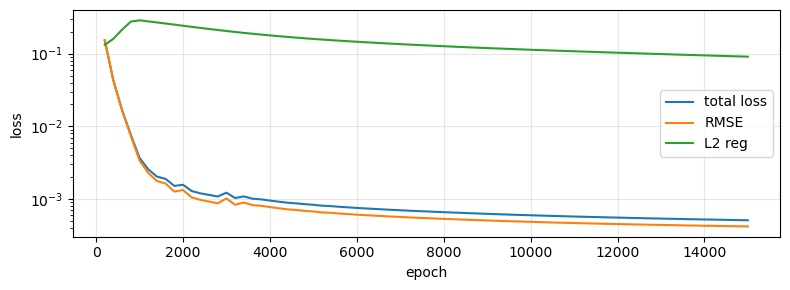

In [18]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.semilogy(history['epoch'], history['loss'], label='total loss')
ax.semilogy(history['epoch'], history['rmse'], label='RMSE')
ax.semilogy(history['epoch'], history['reg'],  label='L2 reg')
ax.set_xlabel('epoch'); ax.set_ylabel('loss'); ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()


## Training quality – visual check

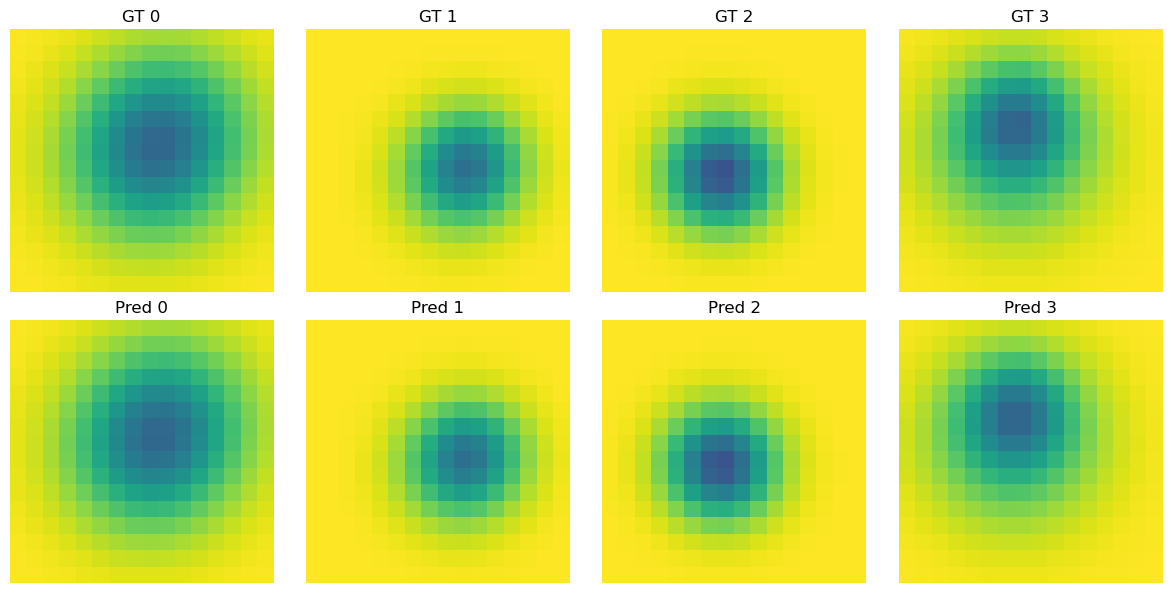

In [19]:
velfield_gt = onp.load('checkpoint3velocityfield16.npy')

fig, axes = plt.subplots(2, min(4, N_TRAIN), figsize=(3*min(4,N_TRAIN), 6))
for col in range(min(4, N_TRAIN)):
    idx_batch = jnp.full(256, col, dtype=jnp.int32)
    pred = onp.array(autodecoder_trained(GRID_NORM, idx_batch)).reshape(16, 16)
    gt   = velfield_gt[col]

    axes[0, col].imshow(gt.T,   origin='lower', vmin=0, vmax=1, cmap='viridis')
    axes[0, col].set_title(f'GT {col}');   axes[0, col].axis('off')
    axes[1, col].imshow(pred.T, origin='lower', vmin=0, vmax=1, cmap='viridis')
    axes[1, col].set_title(f'Pred {col}'); axes[1, col].axis('off')

axes[0,0].set_ylabel('Ground truth'); axes[1,0].set_ylabel('Prediction')
plt.tight_layout(); plt.show()


## Save trained decoder

We save the decoder weights and the distribution of training latent codes (needed for Mahalanobis regularisation at inference).

## Encoder training

Instead of optimising `z*` iteratively with FMM in the loop (very slow),
we train a small **encoder** MLP offline:

```
AT_beat1 (20) + AT_beat2 (20)  →  encoder  →  z*  (latent_dim,)
```

The training targets are the latent codes `z_i` already learnt by the autodecoder.
The inputs are the simulated ATs at the 20 electrode positions for each training scenario.

At inference time the whole pipeline is two forward passes — no FMM, no iteration.


In [20]:
# ── Build encoder training data ──────────────────────────────────────────────
# For each training scenario we need:
#   INPUT : AT at 20 electrodes for beat1 + beat2  (shape: 40,)
#   TARGET: latent code z_i learnt by the autodecoder (shape: latent_dim,)

from scipy.interpolate import RegularGridInterpolator

signals_all  = onp.load('checkpoint3dataset.npy')       # (N_TRAIN, 20, 501)
focal_all    = onp.load('checkpoint3FocalPoints.npy')   # (N_TRAIN, 2, 2)
starting_all = onp.load('checkpoint3starting.npy')      # (N_TRAIN, 2)

T_AXIS_NP = onp.linspace(0, 500, 501)

def extract_AT_all(signals_event, t_ref, window_ms=120.0):
    """Extract AT for all 20 electrodes around t_ref."""
    ATs = []
    for e in range(20):
        dv   = onp.gradient(signals_event[e], T_AXIS_NP)
        mask = (T_AXIS_NP >= max(0, t_ref-window_ms)) & (T_AXIS_NP <= min(500, t_ref+window_ms))
        idx  = onp.argmin(dv[mask])
        ATs.append(T_AXIS_NP[mask][idx])
    return onp.array(ATs)

# Latent codes z_i from the trained autodecoder (our encoder targets)
Z_TARGETS = onp.array(autodecoder_trained.embedder.embedding.value)  # (N_TRAIN, LATENT_DIM)

enc_inputs  = []
enc_targets = []

for i in range(N_TRAIN):
    t0, t1 = starting_all[i]
    AT1 = extract_AT_all(signals_all[i], t0)   # (20,)
    AT2 = extract_AT_all(signals_all[i], t1)   # (20,)

    # Normalise ATs to [0,1] using the signal window (0-500ms)
    feat = onp.concatenate([AT1, AT2]) / 500.0  # (40,)

    enc_inputs.append(feat)
    enc_targets.append(Z_TARGETS[i])

enc_inputs  = jnp.array(onp.stack(enc_inputs))   # (N_TRAIN, 40)
enc_targets = jnp.array(onp.stack(enc_targets))  # (N_TRAIN, LATENT_DIM)

print(f'Encoder inputs  shape: {enc_inputs.shape}')
print(f'Encoder targets shape: {enc_targets.shape}')
print(f'AT input range: [{float(enc_inputs.min()):.3f}, {float(enc_inputs.max()):.3f}]')
print(f'z target range: [{float(enc_targets.min()):.3f}, {float(enc_targets.max()):.3f}]')


Encoder inputs  shape: (13, 40)
Encoder targets shape: (13, 8)
AT input range: [0.008, 0.770]
z target range: [-0.273, 0.295]


Encoder Adam: 100%|██████████| 10000/10000 [00:02<00:00, 3926.93it/s, loss=1.0415e-05]


Final encoder loss: 1.0415e-05


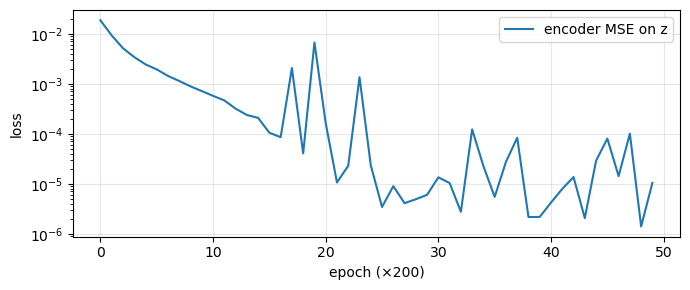

In [21]:
# ── Encoder architecture and training ────────────────────────────────────────

rngs_enc = nnx.Rngs(99)

encoder_mlp = CustomMLP(
    in_features               = 40,          # 20 ATs beat1 + 20 ATs beat2
    out_features              = LATENT_DIM,
    hidden_features           = [64, 64],
    rngs                      = rngs_enc,
    activation_function       = nnx.tanh,
    final_activation_function = None,        # unbounded output (z lives in R^d)
)

@nnx.jit
def enc_loss(model, x, z_gt):
    z_pred = model(x)
    return jnp.mean(jnp.sum(jnp.square(z_pred - z_gt), axis=1))   # MSE on z

@nnx.jit
def enc_train_step(opt, model, x, z_gt):
    grad_fn      = nnx.value_and_grad(enc_loss)
    loss, grads  = grad_fn(model, x, z_gt)
    opt.update(grads)
    return loss

enc_optimizer = nnx.Optimizer(encoder_mlp, optax.adam(1e-3), wrt=nnx.Param)

NUM_ENC = 10000
enc_history = []

pbar_enc = tqdm(range(NUM_ENC), desc='Encoder Adam', dynamic_ncols=True)
for epoch in pbar_enc:
    loss_val = enc_train_step(enc_optimizer, encoder_mlp, enc_inputs, enc_targets)
    if (epoch+1) % 200 == 0:
        enc_history.append(float(loss_val))
        pbar_enc.set_postfix({'loss': f'{float(loss_val):.4e}'})

print(f'Final encoder loss: {enc_history[-1]:.4e}')

fig, ax = plt.subplots(figsize=(7, 3))
ax.semilogy(enc_history, label='encoder MSE on z')
ax.set_xlabel('epoch (×200)'); ax.set_ylabel('loss'); ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()


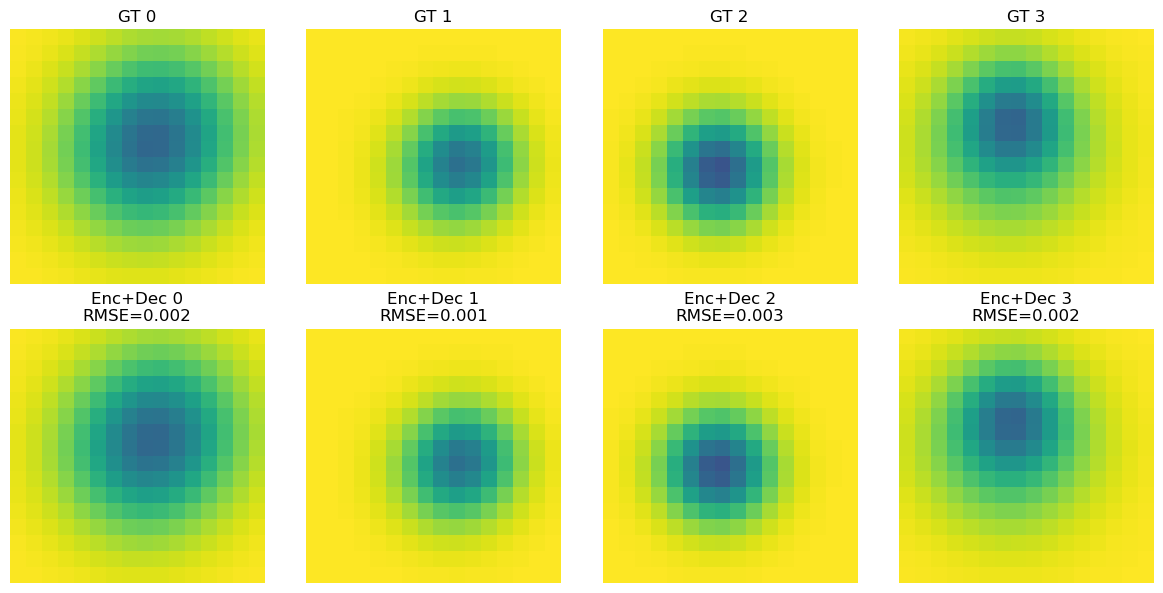

In [22]:
# ── Check encoder quality: predicted z → decoded field vs ground truth ────────

velfield_gt = onp.load('checkpoint3velocityfield16.npy')

fig, axes = plt.subplots(2, min(4, N_TRAIN), figsize=(3*min(4,N_TRAIN), 6))

for col in range(min(4, N_TRAIN)):
    # Predict z from ATs
    z_pred = onp.array(encoder_mlp(enc_inputs[col:col+1]))   # (1, d)

    # Decode z → cnσ on 16×16
    pts   = jnp.array(GRID_NORM)                                       # (256, 2)
    z_    = jnp.tile(jnp.array(z_pred), (256, 1))                     # (256, d)
    x_in  = jnp.concatenate([pts, z_], axis=-1)
    pred  = onp.array(autodecoder_trained.decoder(x_in)).reshape(16,16)

    gt = velfield_gt[col]
    axes[0, col].imshow(gt.T,   origin='lower', vmin=0, vmax=1, cmap='viridis')
    axes[0, col].set_title(f'GT {col}'); axes[0, col].axis('off')
    axes[1, col].imshow(pred.T, origin='lower', vmin=0, vmax=1, cmap='viridis')
    rmse = onp.sqrt(onp.mean((gt - pred)**2))
    axes[1, col].set_title(f'Enc+Dec {col}\nRMSE={rmse:.3f}'); axes[1, col].axis('off')

axes[0,0].set_ylabel('Ground truth'); axes[1,0].set_ylabel('Encoder → Decoder')
plt.tight_layout(); plt.show()


## Save encoder + decoder

In [23]:
import pickle
import jax.tree_util as jtu

# Save raw numpy arrays for both encoder and decoder (no graph_def = no pickle issues)
raw_dec_params = jtu.tree_map(lambda x: onp.array(x), nnx.state(autodecoder_trained))
raw_enc_params = jtu.tree_map(lambda x: onp.array(x), nnx.state(encoder_mlp))

checkpoint = {
    'dec_params': raw_dec_params,
    'enc_params': raw_enc_params,
    'latent_dim': LATENT_DIM,
    'hidden_dec': HIDDEN,
    'hidden_enc': [64, 64],
    'grid_norm':  onp.array(GRID_NORM),
    'n_train':    N_TRAIN,
}

with open('autodecoder_checkpoint.pkl', 'wb') as f:
    pickle.dump(checkpoint, f)

print('Saved encoder + decoder to autodecoder_checkpoint.pkl')


Saved encoder + decoder to autodecoder_checkpoint.pkl


## `GroupSolutionCP3`

Full pipeline at inference — **no FMM, no iteration**:

```
signals → AT (40 values) → encoder → z* → decoder → field16
```

Total time per patient: < 1 second.


In [24]:
import pickle

# ─────────────────────────────────────────────────────────────────
# Constants (must match data generation)
# ─────────────────────────────────────────────────────────────────
_SPLINE_SPACING = onp.array([0.5, 0.7, 1.3, 1.5])
_ANGLES         = onp.array([onp.pi/10.0 + k*2*onp.pi/5 for k in range(5)])
_T_AXIS         = onp.linspace(0, 500, 501)


# ─────────────────────────────────────────────────────────────────
# Helpers
# ─────────────────────────────────────────────────────────────────
def _extract_AT_all(signals_event, t_ref, window_ms=120.0):
    """Return AT (ms) at all 20 electrodes, searched within ±window_ms of t_ref."""
    ATs = []
    for e in range(20):
        dv   = onp.gradient(signals_event[e], _T_AXIS)
        mask = (_T_AXIS >= max(0, t_ref - window_ms)) & (_T_AXIS <= min(500, t_ref + window_ms))
        ATs.append(_T_AXIS[mask][onp.argmin(dv[mask])])
    return onp.array(ATs)


def _restore_models(ckpt):
    """Rebuild encoder and decoder MLPs from checkpoint and load saved weights."""
    import jax.tree_util as jtu
    d           = ckpt['latent_dim']
    h_dec       = ckpt['hidden_dec']
    h_enc       = ckpt['hidden_enc']
    n_train     = ckpt['n_train']
    rngs_       = nnx.Rngs(0)

    # Decoder
    emb_ = nnx.Embed(num_embeddings=n_train, features=d, rngs=rngs_)
    dec_ = CustomMLP(in_features=2+d, out_features=1, hidden_features=h_dec,
                     rngs=rngs_, activation_function=nnx.tanh,
                     final_activation_function=nnx.sigmoid)
    full_model = AutoDecoder(embedder=emb_, decoder=dec_)
    nnx.update(full_model, ckpt['dec_params'])
    decoder_mlp = full_model.decoder

    # Encoder
    enc_ = CustomMLP(in_features=40, out_features=d, hidden_features=h_enc,
                     rngs=rngs_, activation_function=nnx.tanh,
                     final_activation_function=None)
    nnx.update(enc_, ckpt['enc_params'])

    return encoder_mlp, decoder_mlp


# ─────────────────────────────────────────────────────────────────
# Main function  ← signature unchanged
# ─────────────────────────────────────────────────────────────────
def GroupSolutionCP3(signals_event, x_0, y_0, t_0, x_1, y_1, t_1):
    """
    Estimate the slow-conduction velocity field from 20 unipolar signals.

    Parameters
    ----------
    signals_event : (20, 501) ndarray  – unipolar electrograms
    x_0, y_0, t_0 : float             – focal point beat 1 (mm, ms)
    x_1, y_1, t_1 : float             – focal point beat 2 (mm, ms)

    Returns
    -------
    field16 : (16, 16) ndarray  – normalised conduction velocity field cnσ ∈ [0,1]
    """
    # 1. Load encoder + decoder
    with open('autodecoder_checkpoint.pkl', 'rb') as f:
        ckpt = pickle.load(f)
    enc_, dec_ = _restore_models(ckpt)
    grid_norm  = jnp.array(ckpt['grid_norm'])   # (256, 2)
    d          = ckpt['latent_dim']

    # 2. Extract ATs from signals and build input feature vector
    AT1  = _extract_AT_all(signals_event, t_0)          # (20,)
    AT2  = _extract_AT_all(signals_event, t_1)          # (20,)
    feat = jnp.array(onp.concatenate([AT1, AT2]) / 500.0)[None, :]  # (1, 40)

    # 3. Encoder forward pass → z*
    z_star = enc_(feat)                                 # (1, d)

    # 4. Decoder forward pass → cnσ on 16×16
    z_tile = jnp.tile(z_star, (256, 1))                # (256, d)
    x_in   = jnp.concatenate([grid_norm, z_tile], axis=-1)  # (256, 2+d)
    cnσ    = onp.array(dec_(x_in)).ravel()             # (256,)

    field16 = onp.clip(cnσ, 0.0, 1.0).reshape(16, 16)
    return field16


## Quick test on a training scenario

Inference time: 0.049s
field16 shape:  (16, 16)


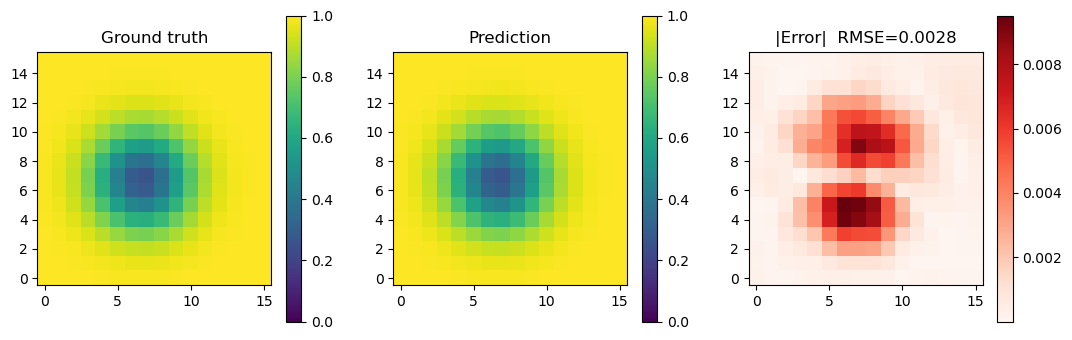

In [25]:
import time

signals_all  = onp.load('checkpoint3dataset.npy')
focal_all    = onp.load('checkpoint3FocalPoints.npy')
starting_all = onp.load('checkpoint3starting.npy')
velfield_gt  = onp.load('checkpoint3velocityfield16.npy')

test_idx = 2
sig_ev   = signals_all[test_idx]
x0, y0   = focal_all[test_idx, 0]
x1, y1   = focal_all[test_idx, 1]
t0, t1   = starting_all[test_idx]

t_start     = time.time()
field_pred  = GroupSolutionCP3(sig_ev, x0, y0, t0, x1, y1, t1)
elapsed     = time.time() - t_start

print(f'Inference time: {elapsed:.3f}s')
print(f'field16 shape:  {field_pred.shape}')

fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
im0 = axes[0].imshow(velfield_gt[test_idx].T, origin='lower', vmin=0, vmax=1, cmap='viridis')
axes[0].set_title('Ground truth'); plt.colorbar(im0, ax=axes[0])

im1 = axes[1].imshow(field_pred.T, origin='lower', vmin=0, vmax=1, cmap='viridis')
axes[1].set_title('Prediction'); plt.colorbar(im1, ax=axes[1])

err = onp.abs(velfield_gt[test_idx] - field_pred)
im2 = axes[2].imshow(err.T, origin='lower', cmap='Reds')
axes[2].set_title(f'|Error|  RMSE={onp.sqrt(onp.mean(err**2)):.4f}')
plt.colorbar(im2, ax=axes[2])

plt.tight_layout(); plt.show()


Inference time: 0.013s
field16 shape:  (16, 16)


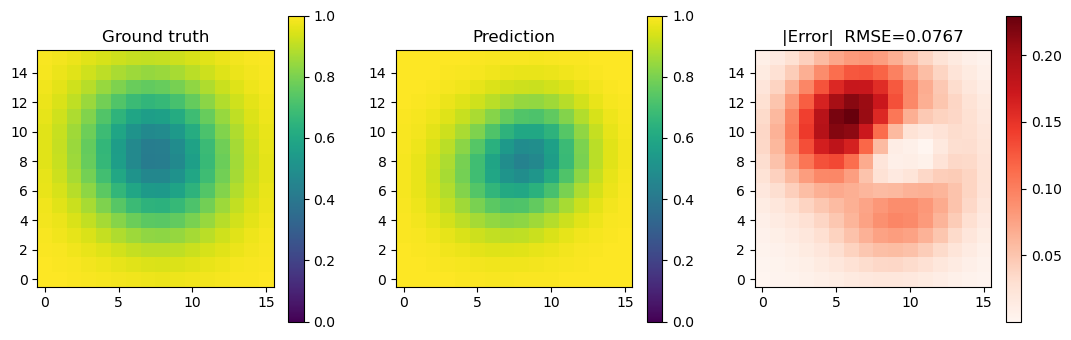

In [29]:
import time

signals_all  = onp.load('checkpoint3dataset_p2.npy')
focal_all    = onp.load('checkpoint3FocalPoints_p2.npy')
starting_all = onp.load('checkpoint3starting_p2.npy')
velfield_gt  = onp.load('checkpoint3velocityfield16_p2.npy')

test_idx = 5
sig_ev   = signals_all[test_idx]
x0, y0   = focal_all[test_idx, 0]
x1, y1   = focal_all[test_idx, 1]
t0, t1   = starting_all[test_idx]

t_start     = time.time()
field_pred  = GroupSolutionCP3(sig_ev, x0, y0, t0, x1, y1, t1)
elapsed     = time.time() - t_start

print(f'Inference time: {elapsed:.3f}s')
print(f'field16 shape:  {field_pred.shape}')

fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
im0 = axes[0].imshow(velfield_gt[test_idx].T, origin='lower', vmin=0, vmax=1, cmap='viridis')
axes[0].set_title('Ground truth'); plt.colorbar(im0, ax=axes[0])

im1 = axes[1].imshow(field_pred.T, origin='lower', vmin=0, vmax=1, cmap='viridis')
axes[1].set_title('Prediction'); plt.colorbar(im1, ax=axes[1])

err = onp.abs(velfield_gt[test_idx] - field_pred)
im2 = axes[2].imshow(err.T, origin='lower', cmap='Reds')
axes[2].set_title(f'|Error|  RMSE={onp.sqrt(onp.mean(err**2)):.4f}')
plt.colorbar(im2, ax=axes[2])

plt.tight_layout(); plt.show()
